<img src="AndrejKarpathy.jpg" alt="Andrej Karpathy" width="160">

这次分享内容一部分来自 Andrej Karpathy 的课程 [Neural Networks: Zero to Hero](https://www.youtube.com/watch?v=VMj-3S1tku0&list=PLAqhIrjkxbuWI23v9cThsA9GvCAUhRvKZ&index=1)，一部分来自来自大模型。

# 训练好的模型本质上是一个函数

一个训练好的大模型，本质上就是一个函数：给定输入，按一套已经定好的计算，得到输出。

$$
y = f(x;\ \theta)
$$

- $x$：输入。一个数、一句话、一张图，都可以是 $x$。
- $\theta$：参数，也就是权重和偏置。这些数决定函数的具体形状。
- $y$：输出。比如类别、下一个字，或者一个数值。

神经网络是把加法、乘法和激活函数（比如 tanh）嵌套、组合成一个函数 $f$。

函数由结构和参数组成。看一个具体的函数：

$$
f(x) = ax^2 + bx + c
$$

这是一个一元二次函数：只有一个输入 $x$，最高次是 $x^2$。这里讨论的就是函数的结构。它约定了这个函数做什么计算操作。

参数是里面可以改的数：$a$、$b$、$c$。取 $a = 3$、$b = -4$、$c = 5$，就得到

$$
f(x) = 3x^2 - 4x + 5
$$

结构没有变，换一组 $a, b, c$，曲线就不一样。



类似的，大模型也能分成结构和参数两部分。

结构就是模型的架构：用不用 Transformer，有多少层、每层多宽、有多少个注意力头，词怎么变成向量，注意力、前馈网络、残差怎么接。这些在训练之前就定好，训练过程中通常不动。

<img src="transformer_figure1.png" alt="Transformer 模型架构" width="420">

图 1：Transformer 的模型结构。引自 Vaswani et al., *Attention Is All You Need*, NIPS 2017, Figure 1.

参数就是每个计算层中的权重，大模型训练就是在调整参数。

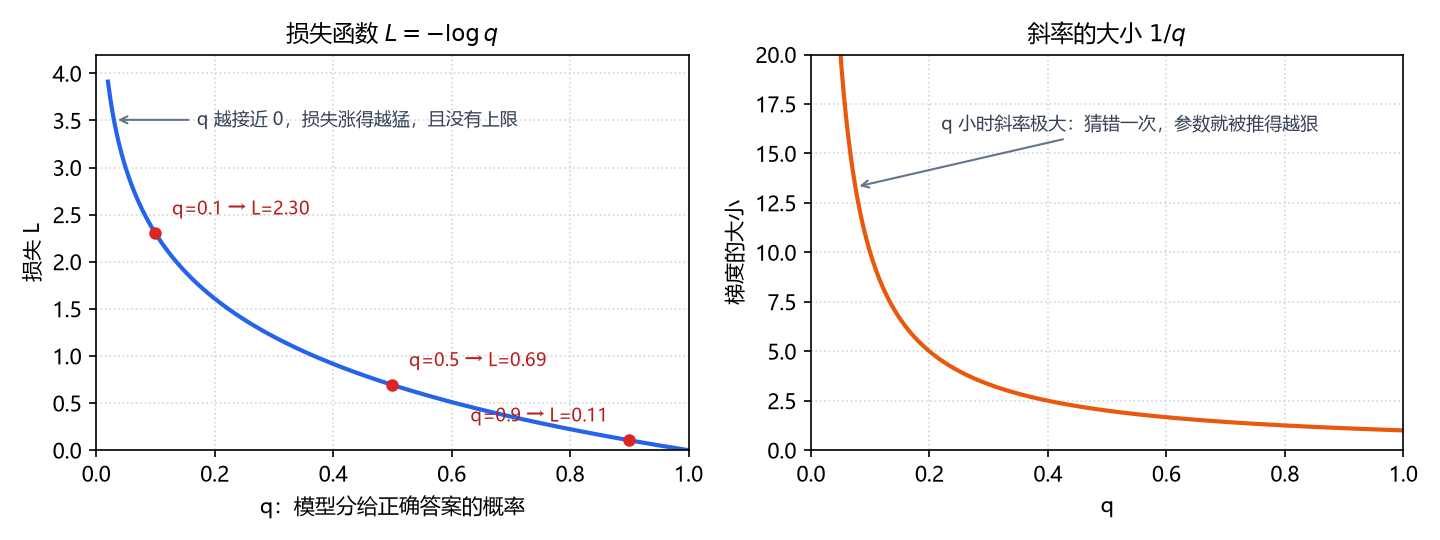

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 中文标签要指定字体，否则会显示成方框
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

q = np.linspace(0.02, 1.0, 500)   # 正确词的概率，取 (0, 1] 这一段
loss = -np.log(q)                 # 交叉熵在正确词那一项上的取值

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.6))

# 左：损失函数本身
ax1.plot(q, loss, color="#2563eb", lw=2)
ax1.set_title(r"损失函数 $L = -\log q$", fontsize=11)
ax1.set_xlabel("q：模型分给正确答案的概率")
ax1.set_ylabel("损失 L")
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 4.2)
ax1.grid(True, color="#d0d7de", ls=":", lw=0.8)

for qi, dx, ha in ((0.9, -10, "right"), (0.5, 8, "left"), (0.1, 8, "left")):
    li = -np.log(qi)
    ax1.plot(qi, li, "o", color="#dc2626", ms=5, zorder=3)
    ax1.annotate(f"q={qi} → L={li:.2f}", xy=(qi, li), xytext=(dx, 9),
                 textcoords="offset points", fontsize=8.5, color="#b91c1c", ha=ha)

ax1.annotate("q 越接近 0，损失涨得越猛，且没有上限",
             xy=(0.03, -np.log(0.03)), xytext=(0.17, 3.45),
             fontsize=8.5, color="#334155",
             arrowprops=dict(arrowstyle="->", color="#64748b", lw=1))

# 右：这条曲线的斜率（取大小），也就是后面讲的梯度
ax2.plot(q, 1 / q, color="#ea580c", lw=2)
ax2.set_title(r"斜率的大小 $1/q$", fontsize=11)
ax2.set_xlabel("q")
ax2.set_ylabel("梯度的大小")
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 20)
ax2.grid(True, color="#d0d7de", ls=":", lw=0.8)
ax2.annotate("q 小时斜率极大：猜错一次，参数就被推得越狠",
             xy=(0.075, 13.3), xytext=(0.22, 16.2),
             fontsize=8.5, color="#334155",
             arrowprops=dict(arrowstyle="->", color="#64748b", lw=1))

fig.tight_layout()
plt.show()

# 大模型训练

训练要解决两件事：1、评判这组参数 “好不好”；2、判断每个参数该往哪个方向改进。

## 损失函数

模型先按当前的参数算出一个预测，再拿它和正确答案比。比完得到一个数，这个数叫损失。损失越大，说明这组参数越差。训练的目标就是把它降下去。

这个损失，目前的大模型主流是用交叉熵来计算。模型要预测的是下一个词：它给词表里每个词一个概率，记作 $q$；正确答案写成分布 $p$，正确词上是 1，其余词上是 0。交叉熵是

$$
H(p, q) = -\sum_i p_i \log q_i
$$

$p$ 只有正确词那一项是 1，公式就收成

$$
L = -\log q_{\text{正确词}}
$$

假设正确答案是「猫」。模型分给「猫」的概率越接近 1，损失越接近 0；这个概率越小，损失越大。

预测一个数值时，常用的是平方误差。前面的二次函数如果希望 $f(2)$ 接近 3，现在算出 10，损失就是 $(10 - 3)^2 = 49$。大模型这里比的是下一个词的概率准不准，所以用上面的交叉熵。

损失也是一个函数。输入是全部参数 $\theta$，输出是一个数。

## 参数怎么改

只知道损失大，还不知道每个参数该往哪边挪。损失对某一个参数的导数，就是这个方向，也叫梯度。

- 梯度为正：这个参数再大一点，损失会升高，所以把它减小一点。
- 梯度为负：这个参数再大一点，损失会降低，所以把它增大一点。

每次挪多远，由学习率决定。学习率太大，会跨过损失较低的位置；太小，则降得很慢。更新写成

$$
\theta \leftarrow \theta - \text{学习率} \times \text{梯度}
$$

二次函数只有 $a$、$b$、$c$ 三个参数，三个都按这个式子改。大模型有几千亿个参数，就对每一个都做同一步。

## 一遍遍重复

一次不把全部数据都看完。拿一小批样本算平均损失和梯度，更新一次参数，再换下一批。这一小批叫一个 batch。

结构不动：有多少层、注意力怎么接，训练过程中保持原样。变的是每一层里面的权重。数据看得越多，这些权重就被推得越接近「下一个词的概率比较准」的那一组。

# 反向传播

上一节每一步更新都要用到梯度。但梯度是怎么算出来的？

损失并不是某个参数的简单函数。它是从输入一路算到输出、再和答案比出来的，中间隔着几十上百层加法和乘法，是一串复合：

$$
L = f_n(\cdots f_2(f_1(x;\ \theta_1);\ \theta_2)\cdots;\ \theta_n)
$$

我们要的是：某个参数动一点点，损失跟着动多少。这是求导。参数有几千亿个，逐个推公式不现实。反向传播（backpropagation）就是算这件事的算法——一次走完，拿到所有参数的梯度。

## 链式法则

复合函数的导数可以拆开再乘起来。拿一个能手算的例子：

$$
u = x \cdot y, \qquad v = u + 1, \qquad L = v^2
$$

取 $x = 2$、$y = 3$，得到 $u = 6$、$v = 7$、$L = 49$。

现在想知道 $x$ 动一点点，$L$ 跟着动多少。从最后一步往回看：$L = v^2$ 对 $v$ 的导数是 $2v$，在 $v = 7$ 处是 14。意思是 $v$ 增加一点，$L$ 大约增加 14 倍那么多。

再往回一层：$v = u + 1$，$u$ 加 1，$v$ 也加 1，导数是 1。乘上去，$u$ 增加一点，$L$ 也是增加 14 倍那么多。

最后一层：$u = xy$ 对 $x$ 的导数是 $y$，也就是 3。三段乘起来

$$
\frac{\partial L}{\partial x} = 14 \times 1 \times 3 = 42
$$

对 $y$ 同理，只是最后一段换成 $x$：$\dfrac{\partial L}{\partial y} = 14 \times 1 \times 2 = 28$。

这个结果能验证。把 $x$ 从 2 改成 2.001，$L$ 变成 $49.042009$，涨了约 $0.042$；除以 $0.001$ 是 $42.009$，和 42 对得上。差的那一点点，来自「动一点点」本身是近似。

## 计算图

上面三行式子其实是一条链：$x, y \to u \to v \to L$。画成图，每个节点是一次运算，箭头是数据流。

前向传播（forward）：从左往右把数值算出来。$u = 6$、$v = 7$、$L = 49$，这些中间结果都得留着，反向时要用。

反向传播（backward）：从 $L$ 出发往左走。每个节点只需要知道自己这一步的局部导数，乘上从右边传回来的梯度，再交给左边。局部导数都很便宜：

| 运算 | 局部导数 |
| --- | --- |
| $z = a + b$ | $\partial z/\partial a = 1$，$\partial z/\partial b = 1$ |
| $z = a \cdot b$ | $\partial z/\partial a = b$，$\partial z/\partial b = a$ |
| $z = a^2$ | $\partial z/\partial a = 2a$ |
| $z = \tanh(a)$ | $\partial z/\partial a = 1 - z^2$ |

加法把梯度原样分给两边，乘法把梯度乘上对方的数值。网络再深，也只是这些运算一层层套起来的。

有个地方要小心：一个节点可能被用到不止一次。这时几条路径都会往它身上传梯度，必须加起来，不能覆盖掉。这叫梯度累加。

## 为什么这样算便宜

如果对每个参数单独求一次导，每条路径都要从头再走一遍，重复的计算量极大。反向传播只走一次：先在前向时把每个节点的数值和局部导数记下来，再从尾部把梯度一层层乘回去。用大约一次前向的代价，拿到全部参数的梯度。

所以大模型「训练一步」里，前向一次、反向一次，反向往回算的那部分就是反向传播。它和损失函数、梯度下降拼在一起，构成一个完整的训练循环。

# 引入 micrograd

概念到这里就齐了：函数、损失、梯度、反向传播。剩下的问题是——这些东西怎么变成能跑的代码。

不用自己写。Karpathy 写了一个很小的自动求导引擎，叫 micrograd。核心就是一个 `Value` 类，一百来行；在它上面再叠一个 `nn.py`，几十行，用来拼神经元和层。

micrograd 只做一件事：**反向传播**。

它不处理张量、不碰 GPU、不做矩阵运算的加速，每个 `Value` 只包一个标量。复杂度被剥干净了，剩下的就是上一节那张计算图：前向计算时把图记下来，反向时沿着图把梯度送到每个参数。

它的工作方式可以直接对上前面讲的：

- `Value` 包住一个数，记两样东西：数值 `data`，和梯度 `grad`。
- 两个 `Value` 做加法、乘法、`tanh`，会生成一个新的 `Value`，同时记下「我这一步的局部导数怎么算」。
- 写完整条前向计算，拿到损失，调用一次 `.backward()`。梯度自动流回每一个参与过计算的 `Value`，写进它的 `grad`。
- 有了 `grad`，就能套上一节的更新式，把参数往降低损失的方向挪一小步。

于是一个神经网络的训练，变成循环里的三件事：前向算损失、反向取梯度、按梯度改参数。全程不需要手推任何公式。

这其实也是 PyTorch 在做的事。`tensor.backward()`、`.grad`、`requires_grad`，名字几乎一样，只是把标量换成了张量，把 Python 的循环换成了矩阵运算。micrograd 是它剥掉工程包装后的样子，小到能把每一步都看清。

接下来就动手：先实现 `Value` 和反向传播，再用它搭一个小多层感知机，拿一批二维点做二分类，看着损失一点点降下去。